In [170]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

### LightGBM
Model ma się uczyć zależności między ilością przepompowanych ścieków, a opadami atmosferycznymi.
Nie tylko przewidywanie pompowania na podstawie poprzednich godzin, ale uwzględnienie jak to reagowało na deszcz

CEL: Wykrywanie sytuacji, w których ilość przepompowanych ścieków jest większa niż powinna być przy danych warunkach opadowych - czy powinniśmy się spodziewać aż tak dużej ilości ścieków?

LightGBM - ma wyznaczać oczekiwane pompowanie (na podtsaiwe historycznej zależności między opadami, porą dnia, ilością ścieków) i
ma wykrywać nadwyżki względem pogody

In [171]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

from przygotowanie_danych_przepompowania import przygotuj_dane_przepompowania_z_opadami

X, y = przygotuj_dane_przepompowania_z_opadami()

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [172]:


# Dwa modele LightGBM:
# 1. Pierwszy przewiduje typową ilość przepompowanych ścieków
# 2. Drugi wyznacza górną granicę oczekiwanego pompowania (Q97) - uwzględniając opady
# Przekroczenie Q97 wskazuje potencjalnie nietypowy dodatkowy dopływ

lgbm = LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                     num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)

lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [173]:
y_pred_val = lgbm.predict(X_val)
q_val = lgbm_q.predict(X_val)

prof = y_train.groupby(y_train.index.hour).median()
base_val = prof.reindex(y_val.index.hour).values

print("MAE modelu:  ", round(mean_absolute_error(y_val, y_pred_val), 2))
print("MAE baseline:", round(mean_absolute_error(y_val, base_val), 2))

MAE modelu:   8.18
MAE baseline: 8.73


Godziny ponad normę: 136 z 2628


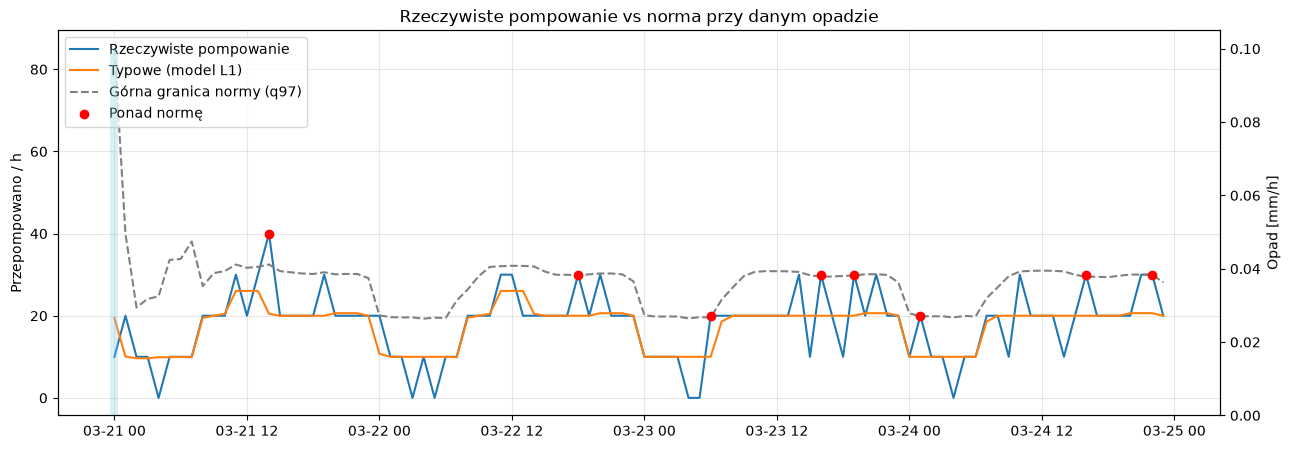

In [174]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_val["opad_0h"],
    "opad_6h": X_val["opad_6h"],
}, index=y_val.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left")
plt.xticks(rotation=30)
plt.show()

In [175]:
# Suma przekroczeń Q97 z ostatnich 6 godzin
results_val["ponad_6h"] = results_val["ponad_q97"].rolling(6, min_periods=6).sum()

# Duże przekroczenie w pojedynczej godzinie
results_val["alarm_pojedynczy"] = results_val["ponad_q97"] > 20

# Mniejsze przekroczenia skumulowane w 6 godzinach
results_val["alarm_skumulowany"] = results_val["ponad_6h"] > 80

# Końcowy alarm
results_val["alarm"] = results_val["alarm_pojedynczy"] | results_val["alarm_skumulowany"]

print("Alarmy pojedyncze:", results_val["alarm_pojedynczy"].sum())
print("Alarmy skumulowane:", results_val["alarm_skumulowany"].sum())

Alarmy pojedyncze: 23
Alarmy skumulowane: 47


# CATBOOST

In [176]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_val)
q_val = cb_q97.predict(X_val)

print("Odsetek przekroczeń Q97 (CatBoost):", round((y_val > q_val).mean() * 100, 2), "%")
print("MAE XGBoost: ", round(mean_absolute_error(y_val, y_pred_val), 2))

Odsetek przekroczeń Q97 (CatBoost): 3.16 %
MAE XGBoost:  8.07


Godziny ponad normę: 83 z 2628


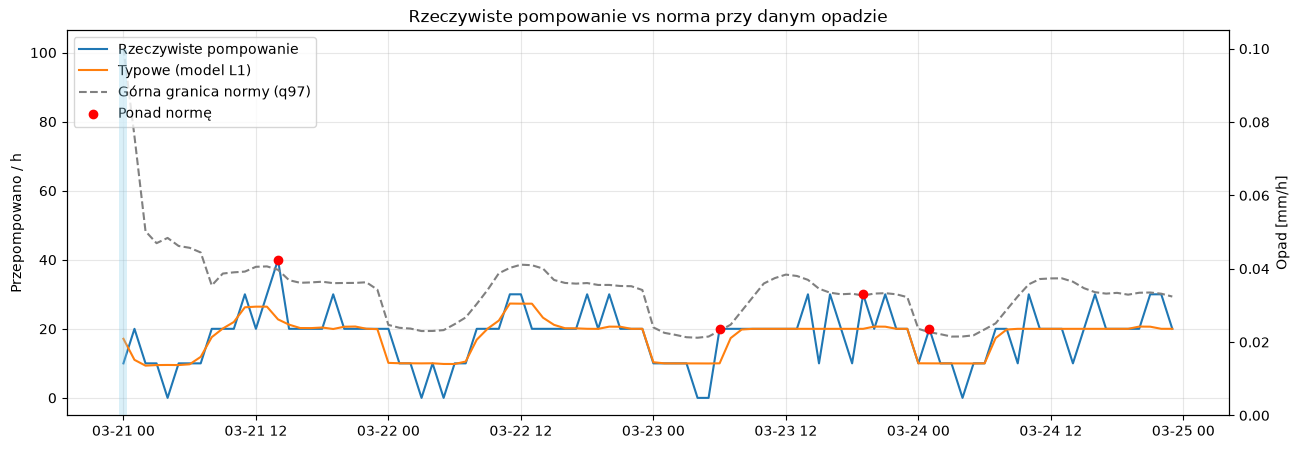

In [177]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_val["opad_0h"],
    "opad_6h": X_val["opad_6h"],
}, index=y_val.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [178]:
# Suma przekroczeń Q97 z ostatnich 6 godzin
results_val["ponad_6h"] = results_val["ponad_q97"].rolling(6, min_periods=6).sum()

# Duże przekroczenie w pojedynczej godzinie
results_val["alarm_pojedynczy"] = results_val["ponad_q97"] > 20

# Mniejsze przekroczenia skumulowane w 6 godzinach
results_val["alarm_skumulowany"] = results_val["ponad_6h"] > 80

# Końcowy alarm
results_val["alarm"] = results_val["alarm_pojedynczy"] | results_val["alarm_skumulowany"]

print("Alarmy pojedyncze:", results_val["alarm_pojedynczy"].sum())
print("Alarmy skumulowane:", results_val["alarm_skumulowany"].sum())

Alarmy pojedyncze: 23
Alarmy skumulowane: 44


In [179]:
anomalie_daty = y_val[y_val > q_val].index

print("Daty wykrytych anomalii:")
for d in anomalie_daty:
  print("->", d)

Daty wykrytych anomalii:
-> 2026-03-08 01:00:00
-> 2026-03-09 09:00:00
-> 2026-03-09 17:00:00
-> 2026-03-09 19:00:00
-> 2026-03-09 20:00:00
-> 2026-03-09 22:00:00
-> 2026-03-10 00:00:00
-> 2026-03-10 20:00:00
-> 2026-03-11 00:00:00
-> 2026-03-11 20:00:00
-> 2026-03-11 22:00:00
-> 2026-03-12 06:00:00
-> 2026-03-21 14:00:00
-> 2026-03-23 06:00:00
-> 2026-03-23 19:00:00
-> 2026-03-24 01:00:00
-> 2026-03-26 02:00:00
-> 2026-03-26 05:00:00
-> 2026-03-28 07:00:00
-> 2026-03-29 00:00:00
-> 2026-03-29 20:00:00
-> 2026-04-04 09:00:00
-> 2026-04-07 21:00:00
-> 2026-04-08 19:00:00
-> 2026-04-09 06:00:00
-> 2026-04-09 17:00:00
-> 2026-04-10 00:00:00
-> 2026-04-12 01:00:00
-> 2026-04-13 18:00:00
-> 2026-04-13 20:00:00
-> 2026-04-14 04:00:00
-> 2026-04-14 06:00:00
-> 2026-04-14 21:00:00
-> 2026-04-15 07:00:00
-> 2026-04-15 08:00:00
-> 2026-04-17 06:00:00
-> 2026-04-26 00:00:00
-> 2026-04-27 19:00:00
-> 2026-04-28 21:00:00
-> 2026-04-29 21:00:00
-> 2026-04-29 22:00:00
-> 2026-04-30 21:00:00
-> 2026-0

# SHAP

In [180]:
#SHAP
import os
from SHAP import generate_shap_from_tree

# LGBM

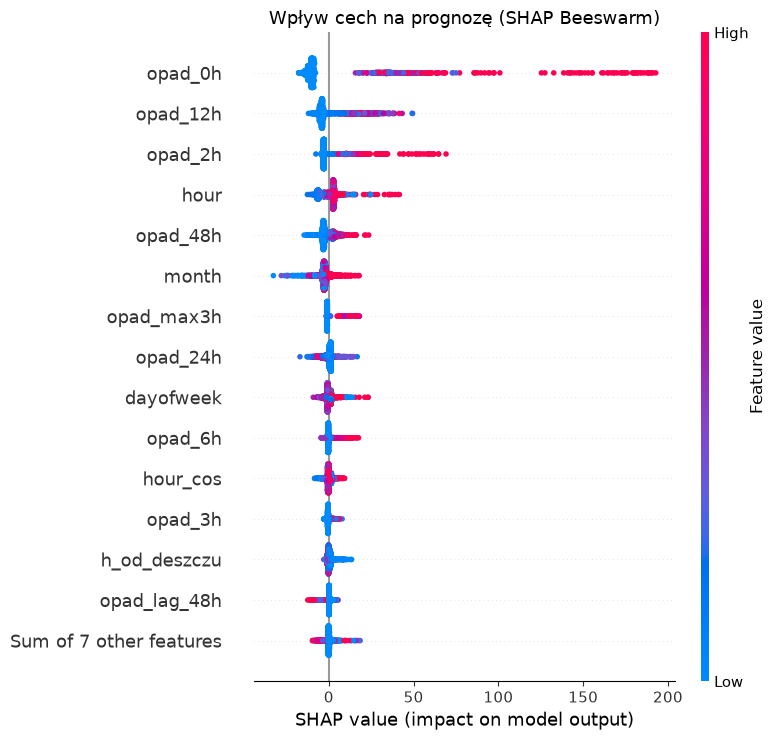

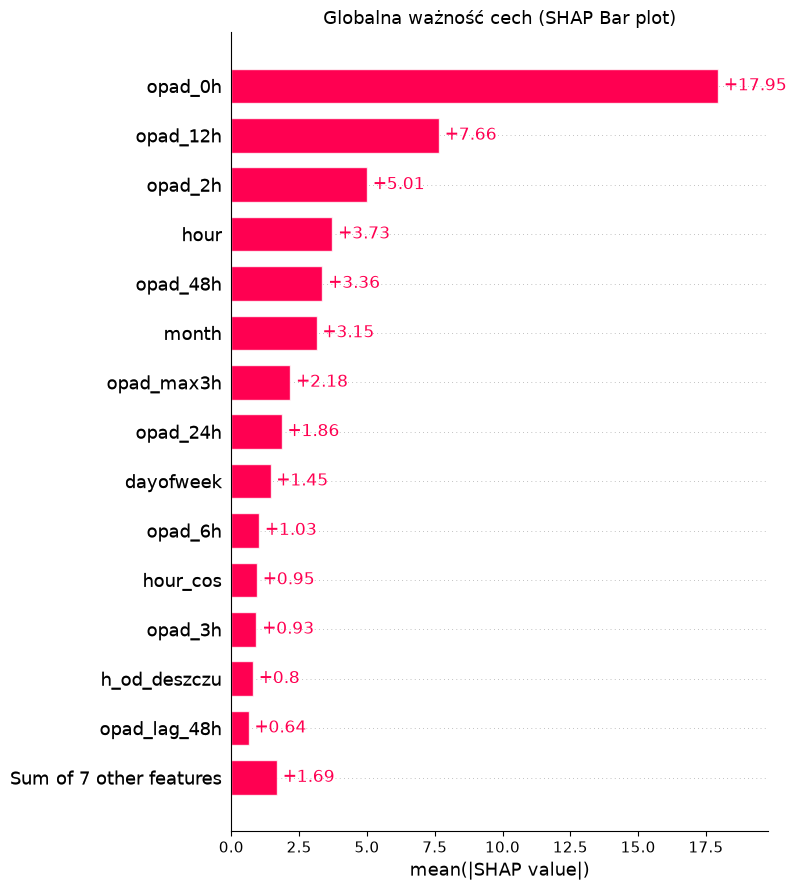

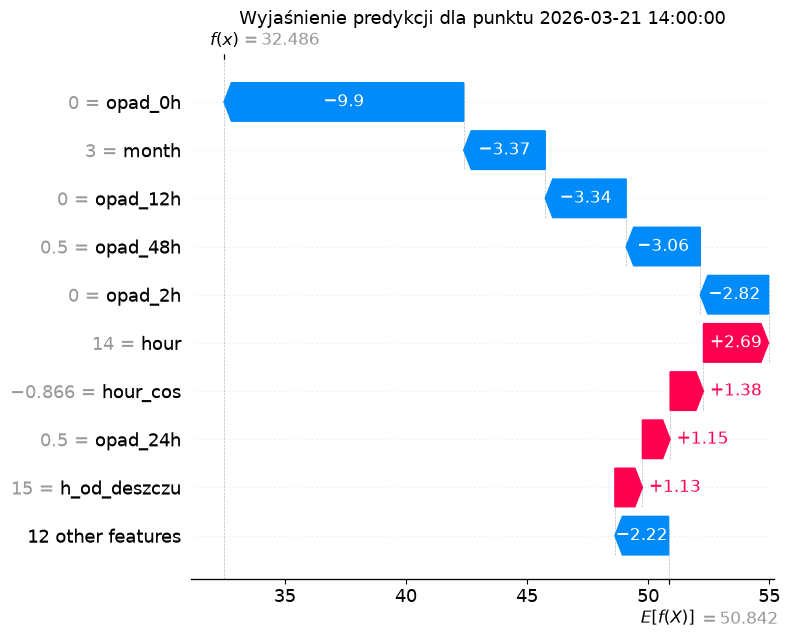

In [181]:
generate_shap_from_tree(lgbm_q,X_val,date_with_time="2026-03-21 14:00:00")

# CATBOOST

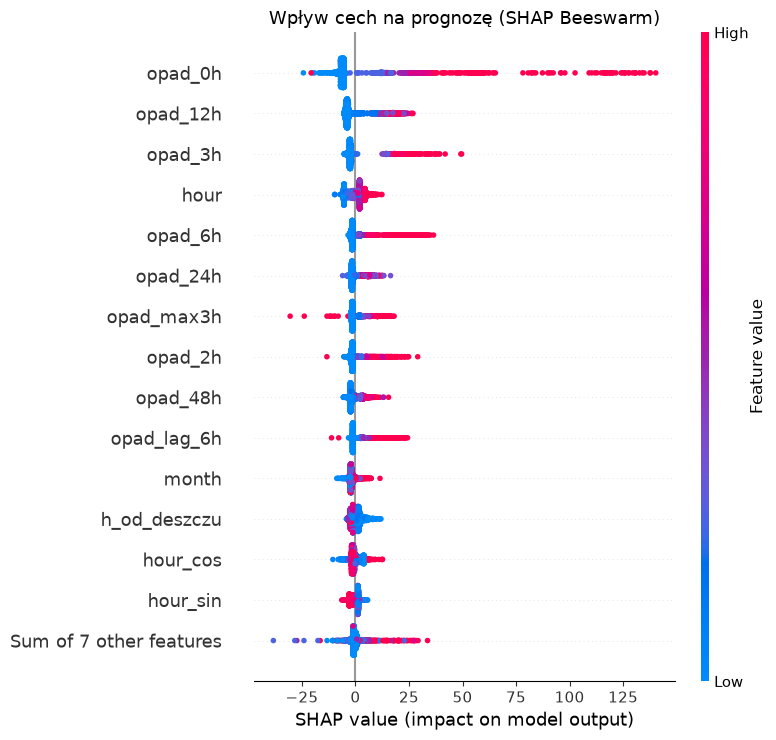

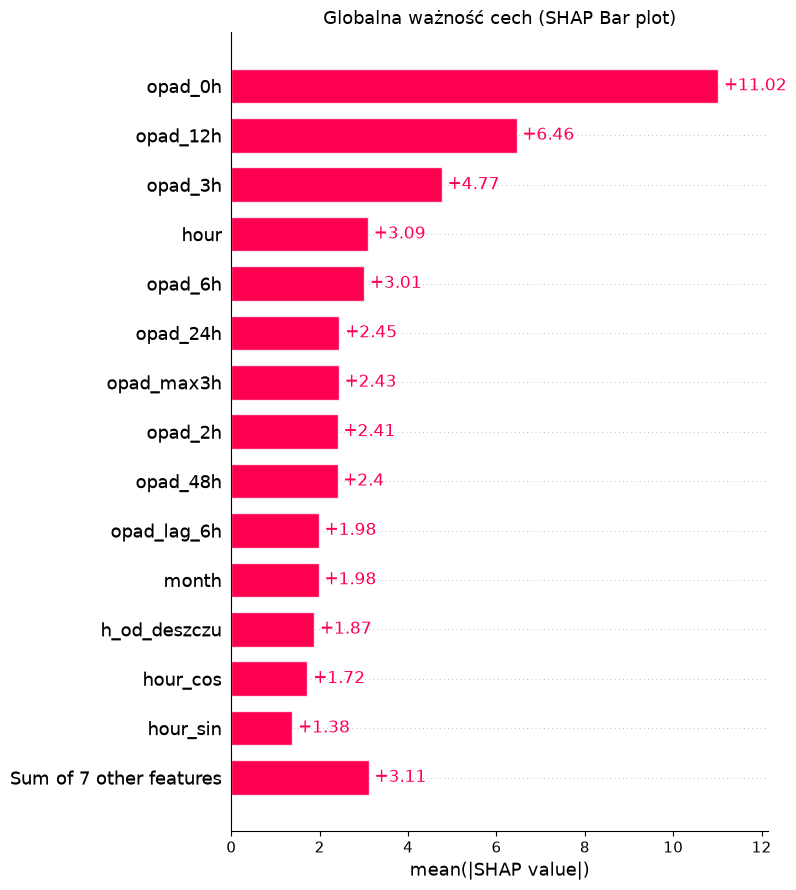

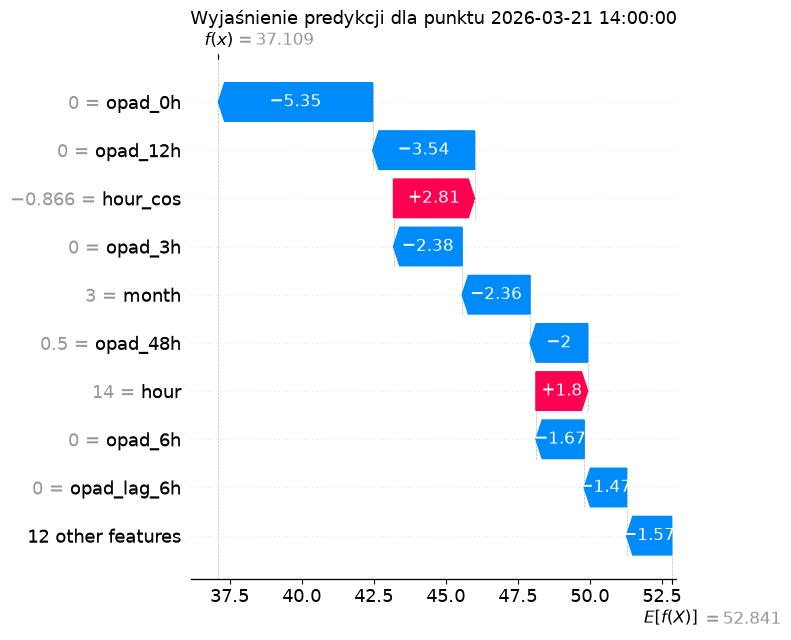

In [182]:
generate_shap_from_tree(cb_q97,X_val,date_with_time="2026-03-21 14:00:00")

# ZUZYCIE ENERGII


In [193]:
przewidziane_pompowanie = lgbm.predict(X)

X_energia = pd.DataFrame({
    'pred_przepompowano': przewidziane_pompowanie
}, index=X.index)

X_energia['hour'] = X_energia.index.hour
X_energia['dayofweek'] = X_energia.index.dayofweek


models_path = Path.cwd().parents[0]
sys.path.append(str(models_path / "Predykcja zużycia energii"))

from przygotowanie_danych_zuzycia_energii import przygotuj_dane_zuzycia_energii

_,y = przygotuj_dane_zuzycia_energii()
X_energia

C:\Users\Tomek\AppData\Local\Temp\ipykernel_22548\3014536674.py:8: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  X_energia['dayofweek'] = X_energia.index.dayofweek


,pred_przepompowano,hour,dayofweek
Data_czas,,,
2024-10-13 01:00:00,20.752213,1,6
2024-10-13 02:00:00,20.345169,2,6
2024-10-13 03:00:00,20.345169,3,6
2024-10-13 04:00:00,20.345169,4,6
2024-10-13 05:00:00,19.279341,5,6
...,...,...,...
2026-10-12 20:00:00,24.496002,20,0
2026-10-12 21:00:00,24.496002,21,0
2026-10-12 22:00:00,24.031890,22,0


In [195]:
train_end = int(len(X_energia) * 0.7)
val_end = int(len(X_energia) * 0.85)

X_train = X_energia.iloc[:train_end]
X_val = X_energia.iloc[train_end:val_end]
X_test = X_energia.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

In [196]:


# Dwa modele LightGBM:
# 1. Pierwszy przewiduje typową ilość przepompowanych ścieków
# 2. Drugi wyznacza górną granicę oczekiwanego pompowania (Q97) - uwzględniając opady
# Przekroczenie Q97 wskazuje potencjalnie nietypowy dodatkowy dopływ

lgbm_energia = LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                     num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_energia.fit(X_train, y_train)

lgbm_q_energia = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q_energia.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [197]:
y_pred_val = lgbm_energia.predict(X_val)
q_val = lgbm_q_energia.predict(X_val)

prof = y_train.groupby(y_train.index.hour).median()
base_val = prof.reindex(y_val.index.hour).values

print("MAE modelu:  ", round(mean_absolute_error(y_val, y_pred_val), 2))
print("MAE baseline:", round(mean_absolute_error(y_val, base_val), 2))


MAE modelu:   1.35
MAE baseline: 1.4


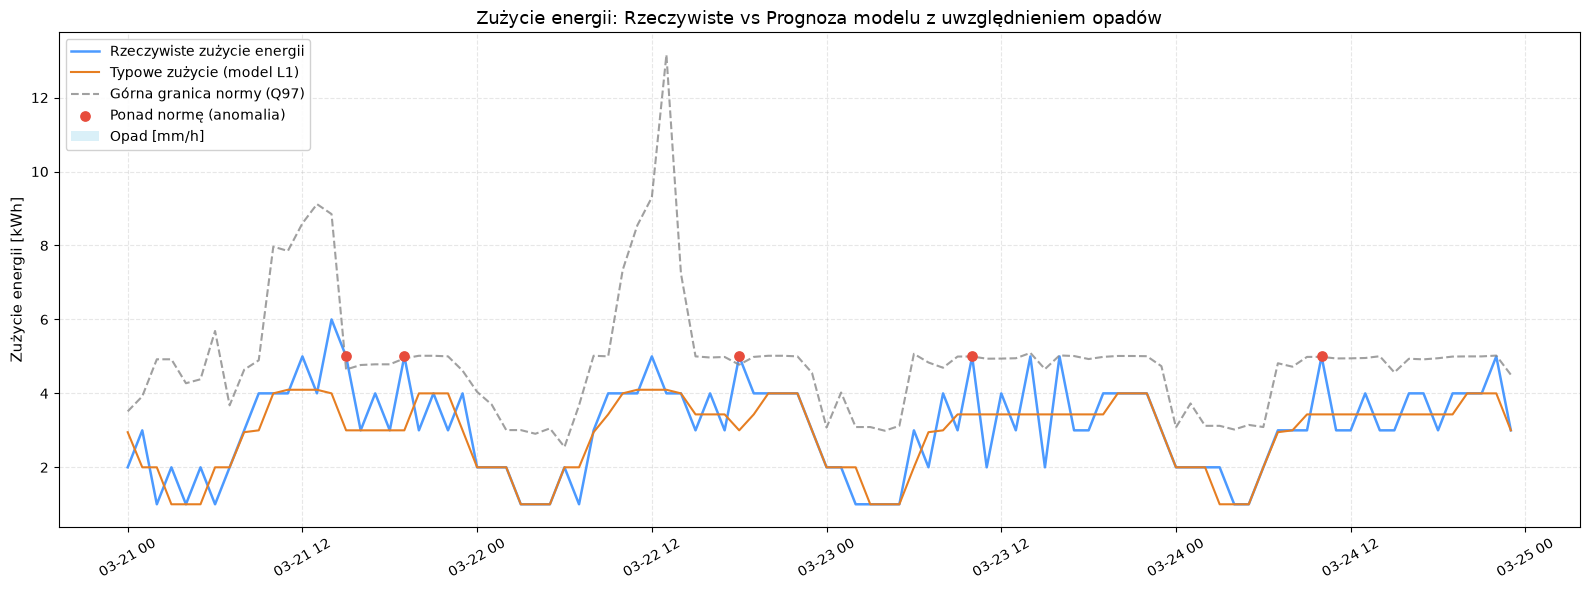

In [198]:
results_val = pd.DataFrame(
    {
        "rzeczywiste": y_val,
        "prognoza": y_pred_val,
        "q97": q_val,
    },
    index=y_val.index,
)

sample = results_val.loc["2026-03-21":"2026-03-24"]

# punkty ponad normę
anomalie = sample[sample["rzeczywiste"] > sample["q97"]]

fig, ax1 = plt.subplots(figsize=(16, 6))

# Oś 1: Zużycie energii
ax1.plot(
    sample.index,
    sample["rzeczywiste"],
    label="Rzeczywiste zużycie energii",
    color="#4C9AFF",
    linewidth=1.8,
)
ax1.plot(
    sample.index,
    sample["prognoza"],
    label="Typowe zużycie (model L1)",
    color="#E67E22",
    linewidth=1.5,
)
if "q97" in sample.columns:
  ax1.plot(
      sample.index,
      sample["q97"],
      label="Górna granica normy (Q97)",
      color="#888888",
      linestyle="--",
      alpha=0.8,
  )
  if len(anomalie) > 0:
    ax1.scatter(
        anomalie.index,
        anomalie["rzeczywiste"],
        color="#E74C3C",
        s=45,
        zorder=5,
        label="Ponad normę (anomalia)",
    )

ax1.set_ylabel("Zużycie energii [kWh]", fontsize=11)
ax1.set_title(
    "Zużycie energii: Rzeczywiste vs Prognoza modelu z uwzględnieniem opadów",
    fontsize=13,
)
ax1.grid(True, linestyle="--", alpha=0.3)


# Połączenie legend z obu osi w jedno okno
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

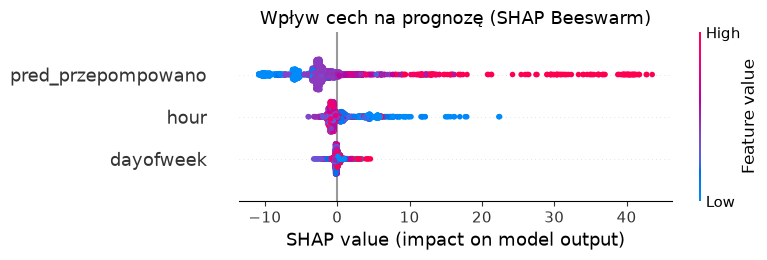

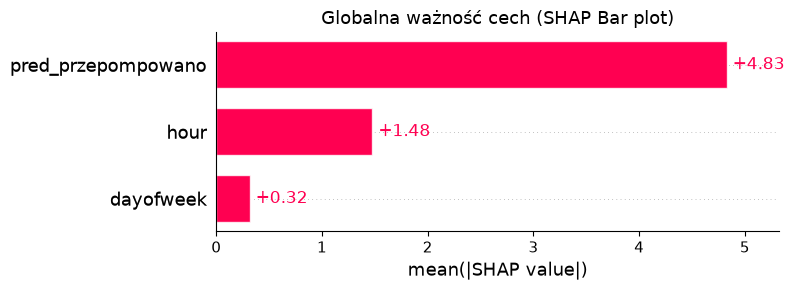

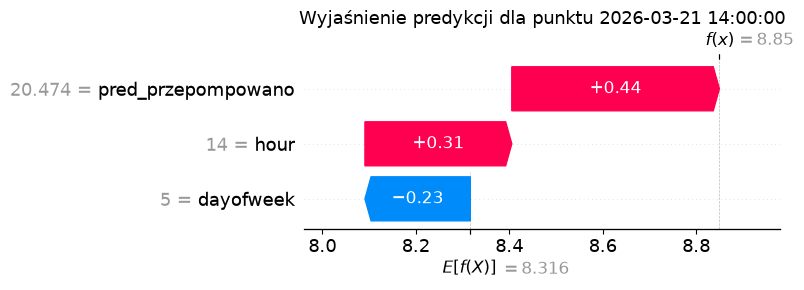

In [200]:
generate_shap_from_tree(lgbm_q_energia,X_val,date_with_time="2026-03-21 14:00:00")